In [1]:
import numpy as np
import matplotlib.pyplot as plt
import pywt as pywt
import json
import glob
import os
import sys
import re

from EggFileReader import EggFileReader
from utils import retrieval, get_quantities

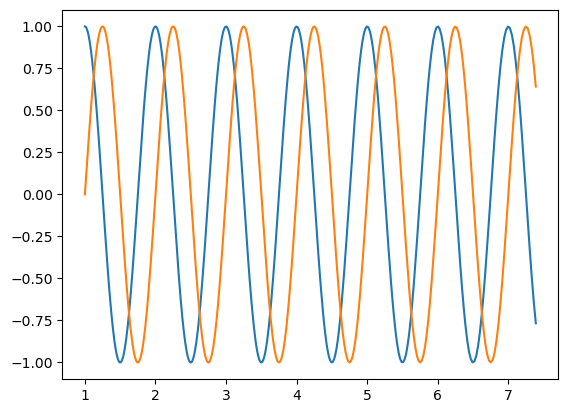

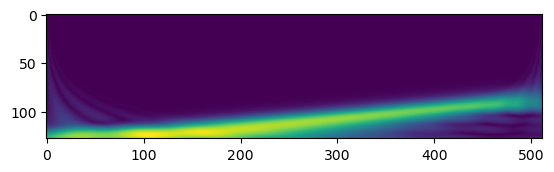

In [23]:
x = np.exp(np.linspace(0, 2, 512))
y = np.cos(2*np.pi*x)+1j*np.sin(2*np.pi*x)  # exponential chirp
plt.plot(x, y.real)
plt.plot(x, y.imag)
plt.show()

scales = np.logspace(np.log10(1), np.log10(128), 128)
coef, freqs = pywt.cwt(y, scales, 'morl')
plt.imshow(np.abs(coef))
plt.show()

In [2]:
I_data = np.load("data/I_1070126132919-360.npy")
Q_data = np.load("data/Q_1070126132919-360.npy")

In [3]:
metadata = get_quantities("data/metadata_1070126132919-360.json")
units = 1e6

fs = float(metadata[0])*units
start = metadata[1][0, 0]
end = metadata[1][1, 0]
print(start, end)
target_f = float(metadata[2])

print(target_f, "Hz, ", target_f/units, "MHz")

0.000406551 0.00075074
141247970.9 Hz,  141.2479709 MHz


In [4]:
start2 = metadata[1][0, 1]
end2 = metadata[1][1, 1]
print(start2, end2)

0.000750741 0.000970397


In [8]:
idx = int(fs*start)
edx = int(fs*end)

I = I_data[idx:edx]
Q = Q_data[idx:edx]

print(len(I)/4)
print(len(Q))

data = (I+1j*Q)**2
#data = I**2
t = np.linspace(start*fs, end*fs, len(I), endpoint=True)

34677.0
138708


In [35]:
print(data)

[-3.56673798e-25+1.23029604e-08j  6.88965782e-07+9.63321799e-06j
  2.06689735e-05-1.42591311e-05j ... -1.35824683e-05+5.77870050e-05j
  6.25974625e-05-6.21299500e-06j -2.87397155e-05-6.24129181e-05j]


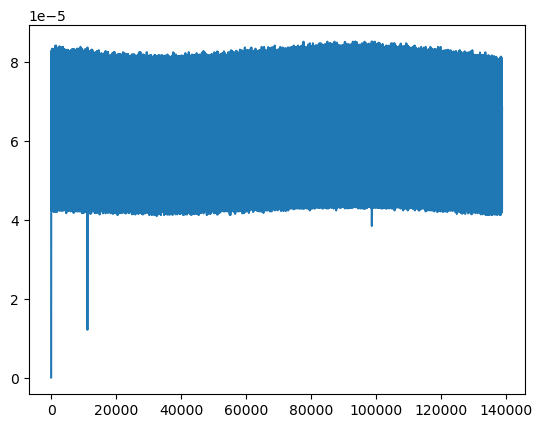

In [36]:
plt.plot(range(len(data)), np.abs(data))
plt.show()

In [11]:
def fmt(ticks):
    if all(isinstance(h, str) for h in ticks):
        return "%s"
    return ("%.d" if all(float(h).is_integer() for h in ticks) else "%.2f")

In [68]:
scales = np.logspace(np.log10(1), np.log10(16), 128)
#scales = np.arange(1, 8)
coef, freqs = pywt.cwt(data, scales, 'cmor1.0-0.14', sampling_period=1/fs)

In [60]:
print(scales)

[ 1.          1.02207146  1.04463006  1.06768657  1.09125197  1.11533749
  1.13995461  1.16511507  1.19083085  1.21711422  1.24397771  1.2714341
  1.29949651  1.32817829  1.35749312  1.38745497  1.41807812  1.44937717
  1.48136703  1.51406296  1.54748053  1.58163568  1.61654468  1.65222418
  1.68869117  1.72596304  1.76405756  1.80299288  1.84278756  1.88346056
  1.92503128  1.96751953  2.01094555  2.05533004  2.10069417  2.14705955
  2.19444828  2.24288295  2.29238664  2.34298295  2.394696    2.44755042
  2.50157143  2.55678475  2.61321671  2.67089421  2.72984474  2.79009638
  2.85167787  2.91461856  2.97894843  3.04469816  3.11189908  3.18058323
  3.25078333  3.32253285  3.39586599  3.4708177   3.5474237   3.6257205
  3.70574544  3.78753663  3.87113308  3.95657463  4.04390199  4.13315679
  4.22438158  4.31761984  4.41291599  4.51031547  4.6098647   4.71161113
  4.81560325  4.92189063  5.03052392  5.14155491  5.25503651  5.37102282
  5.48956911  5.6107319   5.73456892  5.8611392   5.9

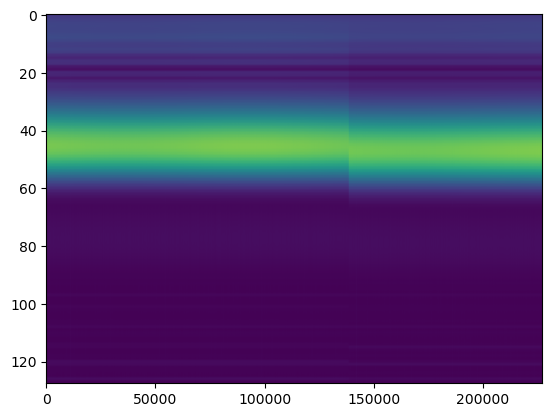

In [17]:
plt.imshow(np.abs(coef), aspect='auto')
plt.show()


In [15]:
c = 200000000/units
print(c)
w0 = target_f/units
print(w0)
ideal_s = c/w0
print(ideal_s)
print(scales)

200.0
141.2479709
1.4159495440935923
[1.         1.01650834 1.0332892  1.05034708 1.06768657 1.0853123
 1.103229   1.12144147 1.13995461 1.15877336 1.17790278 1.197348
 1.21711422 1.23720675 1.25763098 1.27839238 1.29949651 1.32094903
 1.3427557  1.36492237 1.38745497 1.41035954 1.43364223 1.45730928
 1.48136703 1.50582194 1.53068055 1.55594954 1.58163568 1.60774586
 1.63428707 1.66126643 1.68869117 1.71656865 1.74490635 1.77371185
 1.80299288 1.8327573  1.86301307 1.89376832 1.92503128 1.95681035
 1.98911403 2.02195099 2.05533004 2.08926012 2.12375033 2.15880992
 2.19444828 2.23067497 2.2674997  2.30493235 2.34298295 2.3816617
 2.42097898 2.46094531 2.50157143 2.54286821 2.58484673 2.62751825
 2.67089421 2.71498623 2.75980614 2.80536595 2.85167787 2.89875433
 2.94660794 2.99525154 3.04469816 3.09496106 3.14605372 3.19798984
 3.25078333 3.30444836 3.3589993  3.41445079 3.4708177  3.52811512
 3.58635844 3.64556325 3.70574544 3.76692113 3.82910673 3.89231891
 3.95657463 4.02189109 4.0882

/tmp/ipykernel_104034/443542606.py:14: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(np.round(np.array(range(len(coefr)))*units/fs + start, 3))


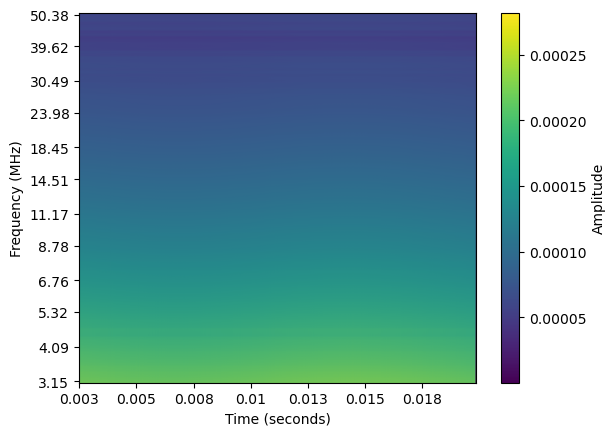

In [69]:
coefr = np.abs(coef)
ticks = freqs / units
num_ticks=12
ii = np.linspace(0, len(ticks) - 1, num_ticks).astype('int32'
                                                     )
yt = np.array([fmt(ticks) % h for h in ticks[ii]])
fig, ax = plt.subplots()
ax.set_yticks(ii)
ax.set_yticklabels(yt)

image = ax.imshow(coefr, aspect='auto')

plt.ylabel("Frequency (MHz)")
ax.set_xticklabels(np.round(np.array(range(len(coefr)))*units/fs + start, 3))
plt.xlabel("Time (seconds)")
fig.colorbar(image, label="Amplitude")
plt.show()

In [33]:
print(freqs)

[3.27437500e+08 3.15163715e+08 3.03350005e+08 2.91979125e+08
 2.81034474e+08 2.70500077e+08 2.60360555e+08 2.50601107e+08
 2.41207485e+08 2.32165977e+08 2.23463384e+08 2.15087002e+08
 2.07024604e+08 1.99264419e+08 1.91795120e+08 1.84605803e+08
 1.77685973e+08 1.71025528e+08 1.64614746e+08 1.58444267e+08
 1.52505085e+08 1.46788530e+08 1.41286256e+08 1.35990231e+08
 1.30892725e+08 1.25986295e+08 1.21263779e+08 1.16718284e+08
 1.12343174e+08 1.08132062e+08 1.04078801e+08 1.00177474e+08
 9.64223856e+07 9.28080543e+07 8.93292038e+07 8.59807559e+07
 8.27578223e+07 7.96556984e+07 7.66698556e+07 7.37959352e+07
 7.10297419e+07 6.83672375e+07 6.58045354e+07 6.33378946e+07
 6.09637142e+07 5.86785284e+07 5.64790014e+07 5.43619222e+07
 5.23242004e+07 5.03628613e+07 4.84750417e+07 4.66579858e+07
 4.49090411e+07 4.32256545e+07 4.16053686e+07 4.00458180e+07
 3.85447262e+07 3.70999018e+07 3.57092358e+07 3.43706979e+07
 3.30823344e+07 3.18422643e+07 3.06486774e+07 2.94998314e+07
 2.83940491e+07 2.732971

In [46]:
coefr = np.abs(coef)

idxs = []
for i in range(len(coefr[0, :])):
    coefri = coefr[:, i]
    idxs.append(np.argmax(coefri))

centerW = int(np.mean(idxs))
stdW = int(np.std(idxs))
print(centerW, stdW)

44 0


In [49]:
#stdW+=1

def fmt(ticks):
    if all(isinstance(h, str) for h in ticks):
        return "%s"
    return ("%.d" if all(float(h).is_integer() for h in ticks) else "%.2f")

ticks = freqs / units
print(ticks)
w = 20
lowlim=centerW-w*stdW
uplim=centerW+w*stdW
ticks_crop = ticks[lowlim:uplim]
print(lowlim, uplim)
coefr_crop = coefr[lowlim:uplim, :]


num_ticks = 12
ii = np.linspace(0, len(ticks_crop) - 1, num_ticks).astype('int32')
yt = np.array([fmt(ticks_crop) % h for h in ticks_crop[ii]])

[327.4375     315.16371515 303.35000527 291.97912472 281.03447435
 270.50007718 260.36055514 250.60110659 241.20748471 232.16597673
 223.46338387 215.08700214 207.0246037  199.26441911 191.79512006
 184.6058029  177.68597268 171.02552787 164.61474556 158.44426732
 152.5050855  146.7885301  141.28625612 135.99023135 130.89272468
 125.98629478 121.26377926 116.71828421 112.34317413 108.13206224
 104.07880118 100.17747402  96.42238561  92.80805428  89.32920384
  85.98075588  82.75782235  79.65569841  76.66985561  73.7959352
  71.02974187  68.36723751  65.80453543  63.33789459  60.9637142
  58.67852844  56.47900141  54.36192224  52.32420042  50.3628613
  48.47504172  46.65798585  44.90904115  43.22565452  41.60536856
  40.04581799  38.54472616  37.0999018   35.70923576  34.37069794
  33.08233436  31.84226425  30.64867739  29.49983136  28.39404908
  27.32971635  26.30527945  25.3192429   24.37016731  23.45666721
  22.57740907  21.73110936  20.91653265  20.13248983  19.37783635
  18.65147057

/tmp/ipykernel_3363221/1802651485.py:10: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(np.round(np.array(range(len(coefr_crop)))*units/fs + start, 3))


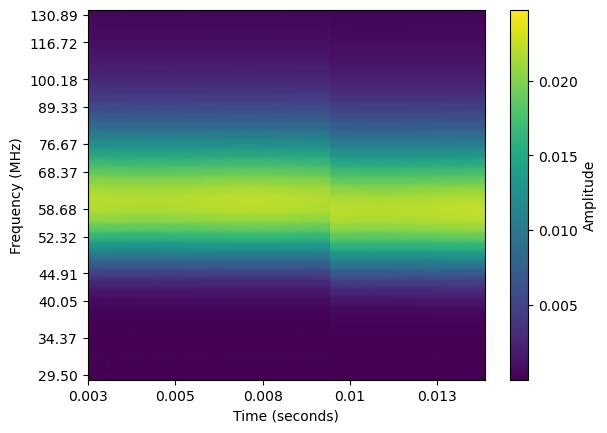

In [50]:
### PLOT

fig, ax = plt.subplots()
ax.set_yticks(ii)
ax.set_yticklabels(yt)

image = ax.imshow(coefr_crop, aspect='auto')

plt.ylabel("Frequency (MHz)")
ax.set_xticklabels(np.round(np.array(range(len(coefr_crop)))*units/fs + start, 3))
plt.xlabel("Time (seconds)")
fig.colorbar(image, label="Amplitude")
plt.show()

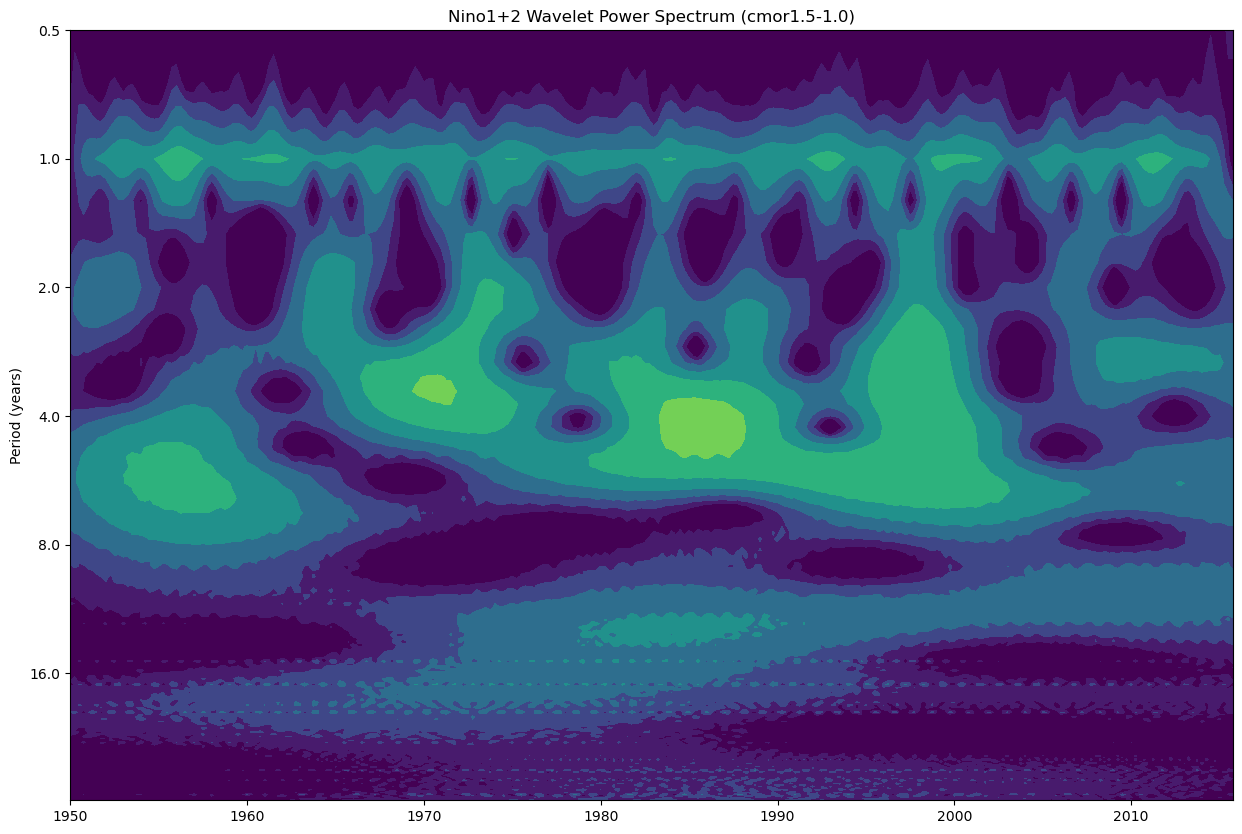

In [26]:
time, sst = pywt.data.nino()
dt = time[1] - time[0]

# Taken from http://nicolasfauchereau.github.io/climatecode/posts/wavelet-analysis-in-python/
wavelet = 'cmor1.5-1.0'
scales = np.arange(1, 128)

[cfs, frequencies] = pywt.cwt(sst, scales, wavelet, dt)
power = (abs(cfs)) ** 2

period = 1. / frequencies
levels = [0.0625, 0.125, 0.25, 0.5, 1, 2, 4, 8]
f, ax = plt.subplots(figsize=(15, 10))
ax.contourf(time, np.log2(period), np.log2(power), np.log2(levels),
            extend='both')

ax.set_title(f'Nino1+2 Wavelet Power Spectrum ({wavelet})')
ax.set_ylabel('Period (years)')
Yticks = 2 ** np.arange(np.ceil(np.log2(period.min())),
                        np.ceil(np.log2(period.max())))
ax.set_yticks(np.log2(Yticks))
ax.set_yticklabels(Yticks)
ax.invert_yaxis()
ylim = ax.get_ylim()
ax.set_ylim(ylim[0], -1)

plt.show()

In [28]:
print(frequencies)

[4.         2.         1.33333333 1.         0.8        0.66666667
 0.57142857 0.5        0.44444444 0.4        0.36363636 0.33333333
 0.30769231 0.28571429 0.26666667 0.25       0.23529412 0.22222222
 0.21052632 0.2        0.19047619 0.18181818 0.17391304 0.16666667
 0.16       0.15384615 0.14814815 0.14285714 0.13793103 0.13333333
 0.12903226 0.125      0.12121212 0.11764706 0.11428571 0.11111111
 0.10810811 0.10526316 0.1025641  0.1        0.09756098 0.0952381
 0.09302326 0.09090909 0.08888889 0.08695652 0.08510638 0.08333333
 0.08163265 0.08       0.07843137 0.07692308 0.0754717  0.07407407
 0.07272727 0.07142857 0.07017544 0.06896552 0.06779661 0.06666667
 0.06557377 0.06451613 0.06349206 0.0625     0.06153846 0.06060606
 0.05970149 0.05882353 0.05797101 0.05714286 0.05633803 0.05555556
 0.05479452 0.05405405 0.05333333 0.05263158 0.05194805 0.05128205
 0.05063291 0.05       0.04938272 0.04878049 0.04819277 0.04761905
 0.04705882 0.04651163 0.04597701 0.04545455 0.04494382 0.04444

In [29]:
print(scales)

[  1   2   3   4   5   6   7   8   9  10  11  12  13  14  15  16  17  18
  19  20  21  22  23  24  25  26  27  28  29  30  31  32  33  34  35  36
  37  38  39  40  41  42  43  44  45  46  47  48  49  50  51  52  53  54
  55  56  57  58  59  60  61  62  63  64  65  66  67  68  69  70  71  72
  73  74  75  76  77  78  79  80  81  82  83  84  85  86  87  88  89  90
  91  92  93  94  95  96  97  98  99 100 101 102 103 104 105 106 107 108
 109 110 111 112 113 114 115 116 117 118 119 120 121 122 123 124 125 126
 127]
